## Data Gathering



*   Use DuckDuckGo for downloading images



In [ ]:
%pip install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 18.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ddgs]




* Download images, based on keyword, for training and validation. The variable `results` below will contain a list of image URLs that is compatible with `fastai`'s `download_images()`.

The main application of this model that will be trained here is for detecting roads with available public parking. Hence, the terms below are sample keywords that would display roads with free parking spots:
* "street parking available"
* "road with empty parking spaces"
* "open roadside parking"
* "empty curbside parking"
* "vacant parking spots on street"

On the other hand, here are the keywords that would results to images of roads with automobiles already parked:
* “street with parked cars”
* “cars parked along the road”
* “roadside parking with cars”
* “curbside parking with vehicles”
* “cars parked on street side”

Based on our application, we can categorize three types of parking:
* residential - refers to the parking spaces in the neighborhood, this include cul de sacs.
* commercial - refers to the parking spaces where businesses rely on customer parking; this usually refers to the avenue or boulevard designated parking lanes.
* informal - refers to ordinary grass or dirt side of the road which are not designated as parking but commonly used as temporary stops.


In [ ]:
from ddgs import DDGS
from pathlib import Path
from fastai.vision.all import *

def search_images(keyword, max_images=100):
    with DDGS() as ddgs:
        results = ddgs.images(
            query = keyword,
            max_results = max_images
        )
    return [result["image"] for result in results]

results = search_images("vacant parking spots on the street")



# parking_types = ("residential", "commercial", "informal")
### GMO: focus only on commercial roadside parking spaces: occupied vs vacant
parking_types = ("vacant", "occupied")
path = Path("parking")
path.mkdir(exist_ok=True)

for parking_type in parking_types:
    dest = path / parking_type
    dest.mkdir(exist_ok=True)

    print(f"Searching for {parking_type} parking images...")

    results = search_images(
        f"{parking_type} roadside parking",
        max_images=100
    )

    # fastai API download_images() has the ff features:
    #     - Fetching each image from the web
    #     - Saving it to a local directory
    #     - Skipping or reporting failed downloads
    #     - Optionally resizing or converting formats after download
    download_images(dest, urls=results)
    print(f"Finished downloading {parking_type} images")

# fastai API to remove unredable or corrupt images
failed = verify_images(get_image_files(path))

for image in failed:
    image.unlink()

print(f"Removed {len(failed)} invalid images")
print(f"Total valid images: {len(get_image_files(path))}")

Searching for vacant parking images...
Finished downloading vacant images
Searching for occupied parking images...
Finished downloading occupied images
Removed 0 invalid images
Total valid images: 134


`DataBlock` is a fastai API used to group datasets by describing the pipeline instead of manually coding each line of code.

In the code below, I have two datasets, one for input and one for output.
* ImageBlock tells us that each item for the input is an image.
* CategoryBlock tells us that the label is a category.

The input to `get_items` is a list of URLs specifying the location of each image.

`RandomSplitter(valid_pct=0.2)` tells us that 20% of the items are reserved for validation set.

`get_y` tells us how to assign label to each item. The input `parent_label` means we use the containing folder name as the label and this is common in image classification problem.

`item_tfms=...` allows transformations to be applied on each item individually.

In [ ]:
parkings = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(128)
)


A `DataLoader` class is a PyTorch class that handles the mechanics of feeding data to your model. Its main functions are:
* Batching — It automatically groups samples into batches, which improves training stability and GPU utilization.
* Shuffling — It randomizes sample order each epoch to reduce overfitting and improve generalization.
* Parallel Loading — It uses multiple worker processes (num_workers) to load and preprocess data concurrently, preventing the CPU from becoming a bottleneck.

In the code below, `path` contains the location of the data.

The `.dataloaders(path)` tells fastai to apply the DataBlock specifications to the data pointed by the `path`.

`dls.show_batch(max_n=9)` tells fastai to take one batch from the training DataLoader and display it using Fastai’s built‑in visualization tools.

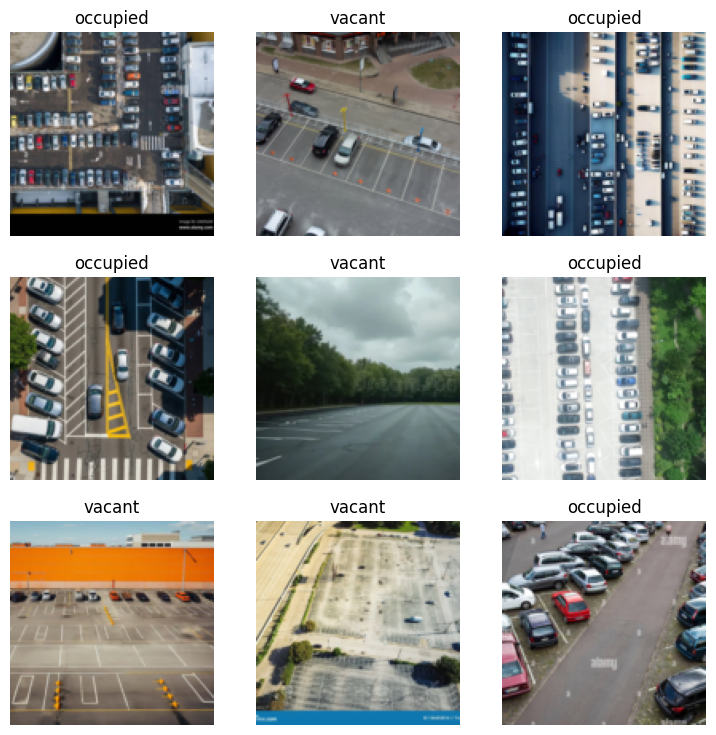

In [ ]:
## DataLoaders
dls = parkings.dataloaders(path)
#dls.show_batch(max_n=9)
dls.show_batch(max_n=9)

## Data Augmentation
* Perform data augmentation so that model is familiar when images are focused on  some regions of the scene.

* On the code below, each item is center cropped on various regions with minimum magnification scale of 50% and then resized to 224 pixels, which is a standard in image classification. After that, the items are grouped in to batches, in our case we only have one batch, and then apply augmentation transforms like rotation, flipping, perspective change, brightness and constrast change.

In [ ]:
parkings = parkings.new(
    item_tfms=RandomResizedCrop(224, min_scale=0.5),
    batch_tfms=aug_transforms())
dls = parkings.dataloaders(path)

## Load a Pretrained Model and Fine Tune it

* In the code below, `resnet18` refers to the pretrained model. ResNet18 is a convolutional neural network with an architecture of 18. Physically, this loads a stack of convolutional layers pretrained on ImageNet, giving the model prior knowledge of edges, textures, shapes, and object features.

* `dls` contains your training and validation datasets, already transformed into batches of tensors.
Physically, this is the stream of images and labels that the model will see during training.

* `error_rate` computes the fraction of incorrect predictions.
Physically, this is what Fastai will display after each epoch to show how well the model is learning.

* The term "fine tune" is used when you train a "pretrained" model. On the other hand, we use "fit" if we want to train a model constructed from scratch.

* `fine_tune(4)` means 1 frozen epoch and 3 unfrozen epochs. If we have `fine_tune()`, this means we have 1 frozen epoch.

* Specifically, `fine_tune` is a two‑phase training procedure designed for transfer learning.

* In Phase 1, we train only the head or the last layer while keeping the body frozen. In other words, Fastai freezes the pretrained convolutional layers while only the final classification head learns. This adapts the model to the new dataset without disturbing the pretrained features. Physically, the model keeps its ImageNet-learned feature detectors (edges, textures, shapes) and only learns how to map those features to your specific classes.

* In Phase 2, we unfreeze and train the whole model. After the first epoch, Fastai unfreezes all layers and trains the entire network for the remaining epochs (in this example, 3 more). It applies discriminative learning rates (lower LR for early layers, higher LR for later layers).
Physically, the model gently adjusts low-level features (edges, textures) and strongly adjusts high-level features (object parts) to better match your dataset.

* This is important because freezing first prevents catastrophic forgetting. Unfreezing later allows deeper adaptation. And discriminative learning rates protect early layers from being overwritten.

In [ ]:
learn = cnn_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(4)

/usr/local/lib/python3.13/dist-packages/fastai/vision/learner.py:304: UserWarning: `cnn_learner` has been renamed to `vision_learner` -- please update your code
  warn("`cnn_learner` has been renamed to `vision_learner` -- please update your code")


epoch,train_loss,valid_loss,error_rate,time
0,1.236501,2.267809,0.384615,00:20


epoch,train_loss,valid_loss,error_rate,time
0,1.246024,1.556528,0.346154,00:23
1,1.101288,0.614559,0.230769,00:23
2,0.968146,0.383782,0.115385,00:23
3,0.791535,0.376198,0.115385,00:22


## Visualize Loss

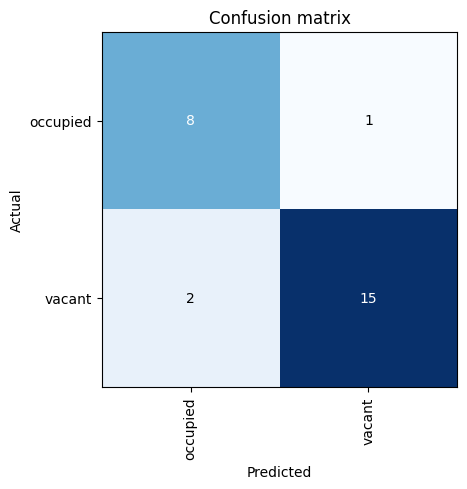

In [ ]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

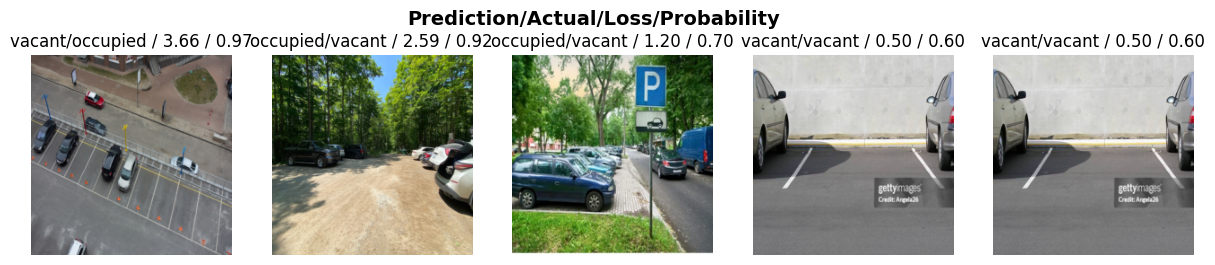

In [ ]:
# The output of plot_top_losses() includes titles for images displaying "prediction/ actual label / loss / probability".
# probability refers to the confidence level that the model assigned to its prediction.
interp.plot_top_losses(5, nrows=1)

## Data Cleaning

* fastai offers an easy way to peform data cleaning

In [ ]:
from fastai.vision.widgets import ImageClassifierCleaner
cleaner = ImageClassifierCleaner(learn)
cleaner

In [ ]:
# After using the GUI above, run the code below to delete some items or label other items with new category
for idx in cleaner.delete(): cleaner.fns[idx].unlink()
#for idx, cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)
for idx, cat in cleaner.change():
    dst = path / cat / cleaner.fns[idx].name
    src = cleaner.fns[idx]

    if dst.exists():
        print(f"Skipping existing file: {dst}")
        continue

    shutil.move(str(src), dst)

## Save the model for later inference

In [ ]:
learn.export()

* Check if the file exists

In [ ]:
path = Path()
path.ls(file_exts='.pkl')

[Path('export.pkl')]

## Load the saved model to perform inference

In [ ]:
learn_inf = load_learner(path/'export.pkl')

/usr/local/lib/python3.13/dist-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


* Before making an inference, check the available categories from the classifier.

In [ ]:
learn_inf.dls.vocab

['occupied', 'vacant']

* Try to make an inference by using one of the already uploaded test data

In [ ]:
learn_inf.predict('/content/parking/occupied/12aeb00c-dc77-403f-9b9e-c5c4c9a9ed97.jpg')

('occupied', tensor(0), tensor([0.8769, 0.1231]))

## Create a Notebook App for the Model

In [ ]:
import ipywidgets as widgets
btn_upload = widgets.FileUpload()
btn_upload


FileUpload(value={}, description='Upload')

* Grab the image that was saved in the btn_upload object.

In [ ]:
img = PILImage.create(btn_upload.data[-1])

* Use an output widget to display it.

In [ ]:
out_pl = widgets.Output()
out_pl.clear_output()
with out_pl: display(img.to_thumb(128,128))
out_pl

Output()

* Use the uploaded image to make predictions and display the results with proper labels.

In [ ]:
pred, pred_idx, probab = learn_inf.predict(img)
lbl_pred = widgets.Label()
lbl_pred.value = f"\nPrediction: {pred}\nProbability: {probab[pred_idx]:.04f}"
lbl_pred

Label(value='\nPrediction: occupied\nProbability: 0.9916')

* Create a button so that it will trigger classication when pressed.

In [ ]:
btn_run = widgets.Button(description="Classify")
btn_run

# event handler for the Classify button
def on_click_classify(change):
    img = PILImage.create(btn_upload.data[-1])
    out_pl.clear_output()
    with out_pl: display(img.to_thumb(128,128))
    pred, pred_idx, probab = learn_inf.predict(img)
    lbl_pred.value = f"\nPrediction: {pred}\nProbability: {probab[pred_idx]:.04f}"

btn_run.on_click(on_click_classify)

* Put all widgets into one vertical box GUI

In [ ]:
from ipywidgets import VBox, Label

VBox([
    widgets.Label("Select your parking spot!"),
    btn_upload,
    btn_run,
    out_pl,
    lbl_pred
])